Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6851 - loss: 1.0034 - val_accuracy: 0.8194 - val_loss: 0.5578
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8203 - loss: 0.5332 - val_accuracy: 0.8323 - val_loss: 0.4866
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8336 - loss: 0.4784 - val_accuracy: 0.8419 - val_loss: 0.4593
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8418 - loss: 0.4561 - val_accuracy: 0.8485 - val_loss: 0.4442
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8525 - loss: 0.4292 - val_accuracy: 0.8528 - val_loss: 0.4298
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8566 - loss: 0.4164 - val_accuracy: 0.8510 - val_loss: 0.4286
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8596 - loss: 0.4064 - val_accuracy: 0.8607 - val_loss: 0.4051
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8625 - loss: 0.3950 - 

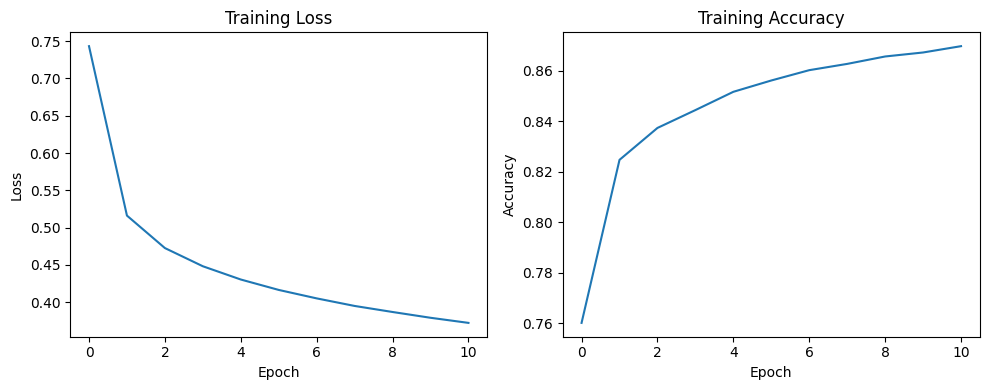

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

train_data = pd.read_csv("Datasets/FNN_CNN/F_MNIST/mnist_train.csv")
test_data = pd.read_csv("Datasets/FNN_CNN/F_MNIST/mnist_test.csv")

y_train = train_data.iloc[:, 0].values
x_train = train_data.iloc[:, 1:].values

y_test = test_data.iloc[:, 0].values
x_test = test_data.iloc[:, 1:].values

x_train = x_train.reshape(-1, 28, 28)
x_test = x_test.reshape(-1, 28, 28)

x_train = x_train / 255.0
x_test = x_test / 255.0

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=11,
    validation_data=(x_test, y_test)
)

loss, accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()